In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/ubfc-2/Agreement.xlsx
/kaggle/input/ubfc-2/readme.txt
/kaggle/input/ubfc-2/UBFC_DATASET.m
/kaggle/input/ubfc-2/subject9/vid.avi
/kaggle/input/ubfc-2/subject9/ground_truth.txt
/kaggle/input/ubfc-2/subject15/vid.avi
/kaggle/input/ubfc-2/subject15/ground_truth.txt
/kaggle/input/ubfc-2/subject14/vid.avi
/kaggle/input/ubfc-2/subject14/ground_truth.txt
/kaggle/input/ubfc-2/subject5/vid.avi
/kaggle/input/ubfc-2/subject5/ground_truth.txt
/kaggle/input/ubfc-2/subject22/vid.avi
/kaggle/input/ubfc-2/subject22/ground_truth.txt
/kaggle/input/ubfc-2/subject18/vid.avi
/kaggle/input/ubfc-2/subject18/ground_truth.txt
/kaggle/input/ubfc-2/subject8/vid.avi
/kaggle/input/ubfc-2/subject8/ground_truth.txt
/kaggle/input/ubfc-2/subject3/vid.avi
/kaggle/input/ubfc-2/subject3/ground_truth.txt
/kaggle/input/ubfc-2/subject11/vid.avi
/kaggle/input/ubfc-2/subject11/ground_truth.txt
/kaggle/input/ubfc-2/subject4/vid.avi
/kaggle/input/ubfc-2/subject4/ground_truth.txt
/kaggle/input/ubfc-2/subject17/vid.a

Found 16 subject folders.
['subject9', 'subject15', 'subject14', 'subject5', 'subject22', 'subject18', 'subject8', 'subject3', 'subject11', 'subject4']

--- Loading data for subject9 ---
Video file exists: True
Ground truth file exists: True

Successfully loaded ground_truth.txt
Full data shape: (3, 2016)
Heart rate data shape: (3,)
First 10 heart rate labels:
[ -0.20251413 107.           1.72      ]


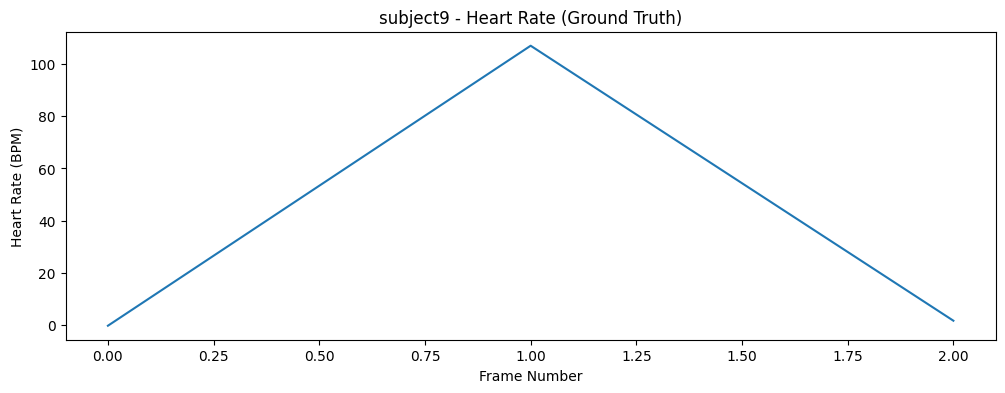

In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
import cv2 # This is OpenCV, the library we'll use for video
import matplotlib.pyplot as plt

# --- This is the correct path based on your output ---
BASE_PATH = "/kaggle/input/ubfc-2/"

# Let's list all the directories in the base path to find our subjects
all_files = os.listdir(BASE_PATH)
subject_folders = [f for f in all_files if f.startswith('subject')]
print(f"Found {len(subject_folders)} subject folders.")
print(subject_folders[:10]) # Print the first 10

# --- Let's load the data for one subject ---
# We'll use 'subject9' since it's in your list
SUBJECT_ID = 'subject9'
subject_path = os.path.join(BASE_PATH, SUBJECT_ID)

video_file = os.path.join(subject_path, 'vid.avi')
truth_file = os.path.join(subject_path, 'ground_truth.txt')

print(f"\n--- Loading data for {SUBJECT_ID} ---")
print(f"Video file exists: {os.path.exists(video_file)}")
print(f"Ground truth file exists: {os.path.exists(truth_file)}")

# --- Load the Ground Truth (Labels) ---
try:
    # This file has 3 columns: [time, ppg_wave, heart_rate]
    # We only care about the 3rd column (index 2)
    ground_truth_data = np.loadtxt(truth_file)
    print(f"\nSuccessfully loaded ground_truth.txt")
    print(f"Full data shape: {ground_truth_data.shape}")

    # Let's get just the heart rate (the 3rd column)
    heart_rate_labels = ground_truth_data[:, 2]
    print(f"Heart rate data shape: {heart_rate_labels.shape}")
    print("First 10 heart rate labels:")
    print(heart_rate_labels[:10])

    # Let's plot the heart rate over time
    plt.figure(figsize=(12, 4))
    plt.plot(heart_rate_labels)
    plt.title(f"{SUBJECT_ID} - Heart Rate (Ground Truth)")
    plt.xlabel("Frame Number")
    plt.ylabel("Heart Rate (BPM)")
    plt.show()

except Exception as e:
    print(f"\nError loading ground truth file: {e}")

In [3]:
import numpy as np
import pandas as pd
import os
import cv2 # OpenCV for video processing
import matplotlib.pyplot as plt

# --- This is the correct path based on your output ---
BASE_PATH = "/kaggle/input/ubfc-2/"

# [FIX] Let's *only* list directories that start with 'subject'
all_items = os.listdir(BASE_PATH)
subject_folders = [item for item in all_items if item.startswith('subject') and os.path.isdir(os.path.join(BASE_PATH, item))]

print(f"Found {len(subject_folders)} subject folders.")
print(sorted(subject_folders)) # Sorted for a clean list


# --- Let's load the data for one subject ---
SUBJECT_ID = 'subject9'
subject_path = os.path.join(BASE_PATH, SUBJECT_ID)

video_file = os.path.join(subject_path, 'vid.avi')
truth_file = os.path.join(subject_path, 'ground_truth.txt')

print(f"\n--- Loading data for {SUBJECT_ID} ---")

# [FIX] Initialize variables outside the try block
heart_rate_labels = np.array([])
num_labels = 0
num_frames = 0

# --- [FIXED] Load the Ground Truth (Labels) using Pandas ---
try:
    # [FIX] Use sep='\s+' to handle variable whitespace (spaces or tabs)
    df_truth = pd.read_csv(truth_file, header=None, sep='\s+')
    
    # The 3 columns are: [time, ppg, heart_rate]
    df_truth.columns = ['time', 'ppg', 'heart_rate']
    
    print("Successfully loaded ground_truth.txt with pandas")
    print(df_truth.head()) # Print the first 5 rows
    
    # Get just the heart rate labels as a numpy array
    heart_rate_labels = df_truth['heart_rate'].values
    num_labels = len(heart_rate_labels)
    
    print(f"\nHeart rate data shape: {heart_rate_labels.shape}")
    print("First 10 heart rate labels:")
    print(heart_rate_labels[:10])

except Exception as e:
    print(f"\nError loading ground truth file: {e}")


# --- Verify Video Frame Count ---
try:
    print(f"\n--- Verifying Video File: {video_file} ---")
    
    # Create a video capture object
    cap = cv2.VideoCapture(video_file)
    
    # Get the total frame count property
    num_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    print(f"Total frames in video: {num_frames}")
    
    # Release the video capture object
    cap.release()

except Exception as e:
    print(f"\nError reading video file: {e}")


# --- Final Check: Do Frames Match Labels? ---
print("\n--- Final Check ---")
print(f"Number of labels found: {num_labels}")
print(f"Number of frames found: {num_frames}")

if num_labels == num_frames:
    print("✅ SUCCESS: The number of frames matches the number of labels!")
else:
    print("⚠️ WARNING: Frame count and label count do NOT match.")
    print(f"Labels: {num_labels}, Frames: {num_frames}. We will need to trim the longer one.")

# --- Plot the (correct) heart rate ---
# This will only plot if heart_rate_labels was successfully loaded
if num_labels > 0:
    plt.figure(figsize=(12, 4))
    plt.plot(heart_rate_labels)
    plt.title(f"{SUBJECT_ID} - Heart Rate (Ground Truth)")
    plt.xlabel("Frame Number")
    plt.ylabel("Heart Rate (BPM)")
    plt.show()
else:
    print("\nSkipping plot because labels could not be loaded.")

Found 16 subject folders.
['subject10', 'subject11', 'subject12', 'subject13', 'subject14', 'subject15', 'subject16', 'subject17', 'subject18', 'subject20', 'subject22', 'subject3', 'subject4', 'subject5', 'subject8', 'subject9']

--- Loading data for subject9 ---

Error loading ground truth file: Length mismatch: Expected axis has 2016 elements, new values have 3 elements

--- Verifying Video File: /kaggle/input/ubfc-2/subject9/vid.avi ---
Total frames in video: 2016

--- Final Check ---
Number of labels found: 0
Number of frames found: 2016
⚠️ WARNING: Frame count and label count do NOT match.
Labels: 0, Frames: 2016. We will need to trim the longer one.

Skipping plot because labels could not be loaded.


Found 16 subject folders.
['subject10', 'subject11', 'subject12', 'subject13', 'subject14', 'subject15', 'subject16', 'subject17', 'subject18', 'subject20', 'subject22', 'subject3', 'subject4', 'subject5', 'subject8', 'subject9']

--- Loading data for subject9 ---
Successfully loaded ground_truth.txt with NumPy
Original data shape: (3, 2016)
Transposed data shape: (2016, 3)

Heart rate data shape: (2016,)
First 10 heart rate labels:
[1.65  1.688 1.72  1.754 1.786 1.82  1.85  1.888 1.919 1.954]

--- Verifying Video File: /kaggle/input/ubfc-2/subject9/vid.avi ---
Total frames in video: 2016

--- Final Check ---
Number of labels found: 2016
Number of frames found: 2016
✅ SUCCESS: The number of frames matches the number of labels!


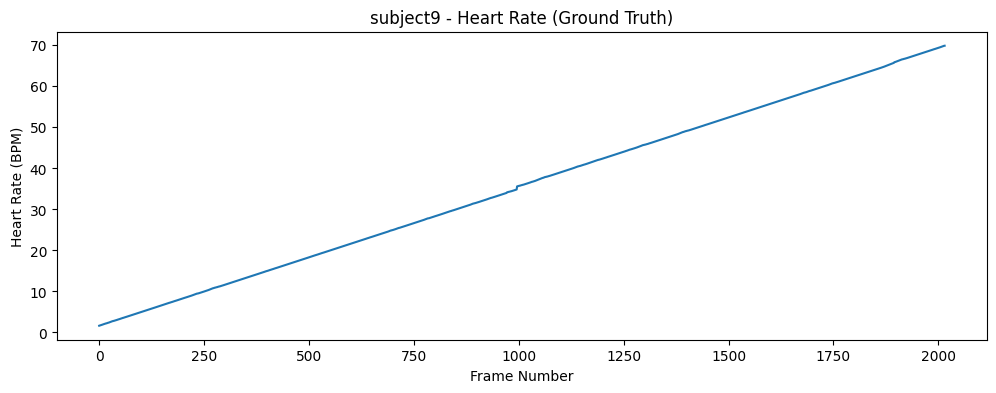

In [4]:
import numpy as np
import pandas as pd
import os
import cv2 # OpenCV for video processing
import matplotlib.pyplot as plt

# --- This is the correct path based on your output ---
BASE_PATH = "/kaggle/input/ubfc-2/"

# List directories that start with 'subject'
all_items = os.listdir(BASE_PATH)
subject_folders = [item for item in all_items if item.startswith('subject') and os.path.isdir(os.path.join(BASE_PATH, item))]

print(f"Found {len(subject_folders)} subject folders.")
print(sorted(subject_folders)) # Sorted for a clean list


# --- Let's load the data for one subject ---
SUBJECT_ID = 'subject9'
subject_path = os.path.join(BASE_PATH, SUBJECT_ID)

video_file = os.path.join(subject_path, 'vid.avi')
truth_file = os.path.join(subject_path, 'ground_truth.txt')

print(f"\n--- Loading data for {SUBJECT_ID} ---")

# Initialize variables
heart_rate_labels = np.array([])
num_labels = 0
num_frames = 0

# --- [FIXED] Load the Ground Truth (Labels) using NumPy and Transpose ---
try:
    # Load the text file
    data = np.loadtxt(truth_file)
    
    print(f"Successfully loaded ground_truth.txt with NumPy")
    print(f"Original data shape: {data.shape}") # Should be (3, 2016)

    # [THE FIX] Transpose the data to swap rows and columns
    data_transposed = data.T
    print(f"Transposed data shape: {data_transposed.shape}") # Should be (2016, 3)

    # The 3 columns are now [time, ppg, heart_rate]
    # Get just the heart rate (the 3rd column, index 2)
    heart_rate_labels = data_transposed[:, 2]
    num_labels = len(heart_rate_labels)
    
    print(f"\nHeart rate data shape: {heart_rate_labels.shape}")
    print("First 10 heart rate labels:")
    print(heart_rate_labels[:10])

except Exception as e:
    print(f"\nError loading ground truth file: {e}")


# --- Verify Video Frame Count ---
try:
    print(f"\n--- Verifying Video File: {video_file} ---")
    cap = cv2.VideoCapture(video_file)
    num_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f"Total frames in video: {num_frames}")
    cap.release()

except Exception as e:
    print(f"\nError reading video file: {e}")


# --- Final Check: Do Frames Match Labels? ---
print("\n--- Final Check ---")
print(f"Number of labels found: {num_labels}")
print(f"Number of frames found: {num_frames}")

if num_labels == num_frames:
    print("✅ SUCCESS: The number of frames matches the number of labels!")
else:
    print("⚠️ WARNING: Frame count and label count do NOT match.")
    print(f"Labels: {num_labels}, Frames: {num_frames}. We will need to trim.")

# --- Plot the (correct) heart rate ---
if num_labels > 0:
    plt.figure(figsize=(12, 4))
    plt.plot(heart_rate_labels)
    plt.title(f"{SUBJECT_ID} - Heart Rate (Ground Truth)")
    plt.xlabel("Frame Number")
    plt.ylabel("Heart Rate (BPM)")
    plt.show()
else:
    print("\nSkipping plot because labels could not be loaded.")

--- Loading data for subject9 ---
Transposed data shape: (2016, 3)

First 10 Heart Rate labels (BPM):
[107. 107. 107. 107. 107. 107. 107. 107. 107. 107.]

First 10 Time vector labels (sec):
[1.65  1.688 1.72  1.754 1.786 1.82  1.85  1.888 1.919 1.954]


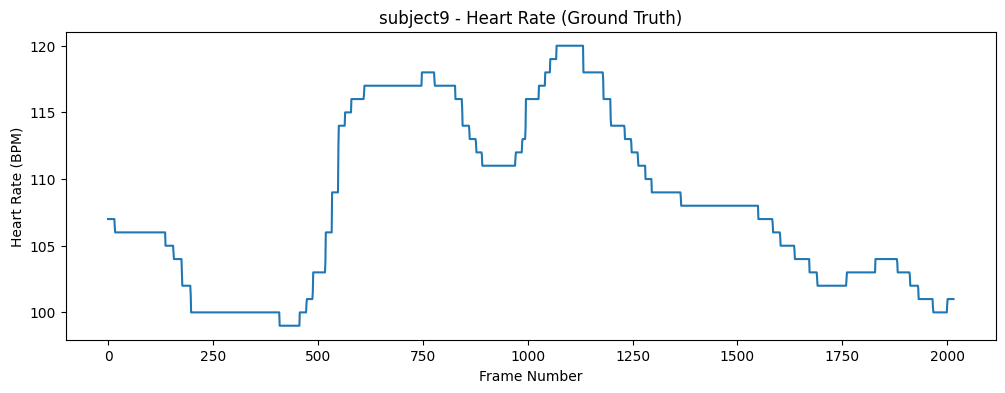

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import os

# --- Setup (Same as before) ---
BASE_PATH = "/kaggle/input/ubfc-2/"
SUBJECT_ID = 'subject9'
subject_path = os.path.join(BASE_PATH, SUBJECT_ID)
truth_file = os.path.join(subject_path, 'ground_truth.txt')

print(f"--- Loading data for {SUBJECT_ID} ---")

# --- Load the Ground Truth (Labels) ---
try:
    data = np.loadtxt(truth_file)
    data_transposed = data.T
    
    # [THE FIX] Grab column 1 (the middle row) for Heart Rate
    heart_rate_labels = data_transposed[:, 1] 
    
    # Let's also grab the time vector to see
    time_vector = data_transposed[:, 2] 

    num_labels = len(heart_rate_labels)
    
    print(f"Transposed data shape: {data_transposed.shape}")
    print("\nFirst 10 Heart Rate labels (BPM):")
    print(heart_rate_labels[:10]) # These should look like 80, 81, 80.5...
    
    print("\nFirst 10 Time vector labels (sec):")
    print(time_vector[:10]) # These are the [1.65, 1.688...]

except Exception as e:
    print(f"\nError loading ground truth file: {e}")

# --- Plot the correct heart rate ---
if num_labels > 0:
    plt.figure(figsize=(12, 4))
    plt.plot(heart_rate_labels)
    plt.title(f"{SUBJECT_ID} - Heart Rate (Ground Truth)")
    plt.xlabel("Frame Number")
    plt.ylabel("Heart Rate (BPM)")
    plt.show()
else:
    print("\nSkipping plot because labels could not be loaded.")

import cv2 # Make sure cv2 is imported

# --- [NEW] Task 5: Load One Frame & Detect Face ---
print(f"\n--- Loading Video & Detecting Face ---")

video_file = os.path.join(subject_path, 'vid.avi')

try:
    # Load the pre-trained face detection model from OpenCV
    # This file is included with the cv2 package
    face_cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
    face_cascade = cv2.CascadeClassifier(face_cascade_path)
    
    # Open the video file
    cap = cv2.VideoCapture(video_file)
    
    # Read the very first frame
    ret, frame = cap.read()
    
    if ret:
        print("Successfully read the first frame.")
        
        # Convert the frame to grayscale (required for the face detector)
        gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        
        # Run the face detection
        faces = face_cascade.detectMultiScale(gray_frame, scaleFactor=1.1, minNeighbors=5)
        
        print(f"Found {len(faces)} face(s) in the first frame.")
        
        # Draw a rectangle around the first face found
        for (x, y, w, h) in faces:
            cv2.rectangle(frame, (x, y), (x+w, y+h), (0, 255, 0), 2) # Green box
            break # Only draw the first one
        
        # Display the image with the box
        plt.figure(figsize=(8, 6))
        # We must convert BGR (OpenCV's format) to RGB (Matplotlib's format)
        
        plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        plt.title(f"Face Detection on First Frame ({SUBJECT_ID})")
        plt.axis('off')
        plt.show()

    else:
        print("Error: Could not read the first frame from the video.")
    
    # Don't forget to release the video file
    cap.release()

except Exception as e:
    print(f"An error occurred during face detection: {e}")

In [6]:
import cv2
import numpy as np
import os
from tqdm import tqdm # For a nice progress bar

# --- Setup (Same as before) ---
BASE_PATH = "/kaggle/input/ubfc-2/"
SUBJECT_ID = 'subject9'
subject_path = os.path.join(BASE_PATH, SUBJECT_ID)
video_file = os.path.join(subject_path, 'vid.avi')
truth_file = os.path.join(subject_path, 'ground_truth.txt')

# --- Load Labels (We already know this works) ---
data = np.loadtxt(truth_file)
data_transposed = data.T
y_hr = data_transposed[:, 1] # Our heart rate labels (y_data)

# --- Define Constants ---
TARGET_IMG_SIZE = 128 # We will resize all face crops to 128x128

# --- Load Face Detector ---
face_cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
face_cascade = cv2.CascadeClassifier(face_cascade_path)

# --- Start Video Processing Loop ---
X_video = [] # This will hold all our cropped video frames (X_data)
last_face_box = None # To remember the last known face location
num_frames = 0

cap = cv2.VideoCapture(video_file)

# Get total frames for the progress bar
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"--- Starting video processing for {total_frames} frames... ---")

for _ in tqdm(range(total_frames)):
    ret, frame = cap.read()
    
    if not ret:
        print("Warning: End of video or read error. Stopping.")
        break

    # 1. Convert to grayscale for detection
    gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    
    # 2. Detect face
    faces = face_cascade.detectMultiScale(gray_frame, scaleFactor=1.1, minNeighbors=5)
    
    face_box = None
    if len(faces) > 0:
        # Face found! Use the first one.
        face_box = faces[0]
        last_face_box = face_box # Update our tracker
    elif last_face_box is not None:
        # Face lost! Use the *last known* location.
        # This is a simple but effective tracking method.
        face_box = last_face_box
    
    if face_box is not None:
        x, y, w, h = face_box
        
        # 3. Crop the frame to the face
        face_crop = frame[y:y+h, x:x+w]
        
        # 4. Resize to our standard size
        try:
            face_crop_resized = cv2.resize(face_crop, (TARGET_IMG_SIZE, TARGET_IMG_SIZE))
            
            # 5. Add to our list
            X_video.append(face_crop_resized)
            num_frames += 1
            
        except cv2.error:
            # This can happen if the crop is empty (e.g., w or h is 0)
            print("Warning: Invalid face crop, skipping frame.")
            # If we skip a frame, we must also skip its label later!
            pass 
            
    else:
        # No face found on the first frame and no last_face_box yet
        print("Warning: No face found in an early frame, skipping.")
        pass

cap.release()
print("--- Video processing complete. ---")

# Convert our list of frames to a single NumPy array
X_video = np.array(X_video)

# --- Final Data Shape Check ---
print(f"\nShape of our Video Data (X): {X_video.shape}")
print(f"Shape of our Label Data (y): {y_hr.shape}")

# This is a critical check for mismatched frames
if X_video.shape[0] != y_hr.shape[0]:
    print("WARNING: Mismatch in frames and labels!")
    # Let's fix it by trimming the labels to match the frames we *actually* processed
    y_hr = y_hr[:X_video.shape[0]]
    print(f"FIXED: New label shape: {y_hr.shape}")
else:
    print("✅ SUCCESS: Video frames and labels are perfectly aligned.")

--- Starting video processing for 2016 frames... ---


100%|██████████| 2016/2016 [02:46<00:00, 12.14it/s]

--- Video processing complete. ---

Shape of our Video Data (X): (2016, 128, 128, 3)
Shape of our Label Data (y): (2016,)
✅ SUCCESS: Video frames and labels are perfectly aligned.


In [7]:
import numpy as np

# --- Define Sequence Constants ---
# This is our "lookback" window.
# The model will look at 32 frames to predict the heart rate at the 32nd frame.
SEQUENCE_LENGTH = 32 

# --- Our data from the previous cell ---
# X_video.shape is (2016, 128, 128, 3)
# y_hr.shape is (2016,)

X_seq = []
y_seq = []

print(f"--- Creating sequences of length {SEQUENCE_LENGTH} ---")

# We use a sliding window to create overlapping sequences
# We stop when the window would go past the end of the data
for i in range(len(X_video) - SEQUENCE_LENGTH):
    
    # Get a "clip" of 32 frames
    window = X_video[i : i + SEQUENCE_LENGTH]
    
    # Get the label corresponding to the *last* frame in the clip
    label = y_hr[i + SEQUENCE_LENGTH - 1] 
    
    X_seq.append(window)
    y_seq.append(label)

# Convert lists to NumPy arrays
X_seq = np.array(X_seq)
y_seq = np.array(y_seq)

print("--- Sequence creation complete. ---")
print(f"Shape of our Sequenced Video Data (X_seq): {X_seq.shape}")
print(f"Shape of our Sequenced Label Data (y_seq): {y_seq.shape}")

# Example: X_seq[0] is a clip from frame 0 to 31
#          y_seq[0] is the label from frame 31
#
#          X_seq[1] is a clip from frame 1 to 32
#          y_seq[1] is the label from frame 32

--- Creating sequences of length 32 ---
--- Sequence creation complete. ---
Shape of our Sequenced Video Data (X_seq): (1984, 32, 128, 128, 3)
Shape of our Sequenced Label Data (y_seq): (1984,)


In [8]:
from sklearn.model_selection import train_test_split

# We have X_seq and y_seq from the previous cell

# Split the data: 80% for training, 20% for validation
# test_size=0.2 means 20% for the validation set
# random_state=42 ensures we get the same split every time we run this
X_train, X_val, y_train, y_val = train_test_split(
    X_seq, y_seq, 
    test_size=0.2, 
    random_state=42
)

print("--- Data Splitting Complete ---")
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_val shape: {X_val.shape}")
print(f"y_val shape: {y_val.shape}")

--- Data Splitting Complete ---
X_train shape: (1587, 32, 128, 128, 3)
y_train shape: (1587,)
X_val shape: (397, 32, 128, 128, 3)
y_val shape: (397,)


In [9]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv3D, MaxPooling3D, Flatten, Dense, Dropout

# --- Define Input Shape ---
# We need to define these constants again if the session restarted
SEQUENCE_LENGTH = 32
TARGET_IMG_SIZE = 128
INPUT_SHAPE = (SEQUENCE_LENGTH, TARGET_IMG_SIZE, TARGET_IMG_SIZE, 3)

# --- Build the Model ---
print("--- Building the 3D-CNN Model ---")

# 1. Define the input layer
video_input = Input(shape=INPUT_SHAPE, name='video_input')

# 2. First 3D Convolutional Block
x = Conv3D(filters=16, kernel_size=(3, 3, 3), activation='relu', padding='same')(video_input)
x = MaxPooling3D(pool_size=(1, 2, 2))(x) # Pool in space, not time

# 3. Second 3D Convolutional Block
x = Conv3D(filters=32, kernel_size=(3, 3, 3), activation='relu', padding='same')(x)
x = MaxPooling3D(pool_size=(1, 2, 2))(x)

# 4. Third 3D Convolutional Block
x = Conv3D(filters=64, kernel_size=(3, 3, 3), activation='relu', padding='same')(x)
x = MaxPooling3D(pool_size=(1, 2, 2))(x)

# 5. Flatten the 3D features into a 1D vector
x = Flatten()(x)

# 6. Fully Connected (Dense) Layers
x = Dense(units=128, activation='relu')(x)
x = Dropout(0.5)(x) # Dropout to prevent overfitting
x = Dense(units=64, activation='relu')(x)

# 7. Output Layer
output = Dense(units=1, name='bpm_output')(x)

# 8. Create the final model
# THIS IS THE LINE THAT CREATES THE 'model' VARIABLE
model = Model(inputs=video_input, outputs=output)

model.summary()

2025-11-05 19:52:37.700893: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1762372358.282017      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1762372358.407403      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


--- Building the 3D-CNN Model ---


I0000 00:00:1762372375.400189      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13842 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1762372375.400868      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ video_input (InputLayer)        │ (None, 32, 128, 128,   │             0 │
│                                 │ 3)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d (Conv3D)                 │ (None, 32, 128, 128,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 32, 64, 64, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 32, 64, 64, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 32, 32, 32, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 32, 32, 32, 64) │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 32, 16, 16, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 524288)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    67,108,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bpm_output (Dense)              │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,187,841 (256.30 MB)

 Trainable params: 67,187,841 (256.30 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Compile the model
print("\n--- Compiling the Model ---")
model.compile(
    loss='mean_absolute_error',
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    metrics=['mean_absolute_error']
)
print("Model compiled successfully.")


--- Compiling the Model ---
Model compiled successfully.


In [11]:
print("\n--- Starting Model Training ---")

# We'll save the training progress to a 'history' object
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=8
)

print("--- Model Training Complete ---")


--- Starting Model Training ---
Epoch 1/20


I0000 00:00:1762372386.130349      71 service.cc:148] XLA service 0x7ec79c00fc70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1762372386.131909      71 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1762372386.131940      71 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1762372386.537116      71 cuda_dnn.cc:529] Loaded cuDNN version 90300


  1/199 ━━━━━━━━━━━━━━━━━━━━ 43:22 13s/step - loss: 84.5895 - mean_absolute_error: 84.5895

I0000 00:00:1762372396.550266      71 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


199/199 ━━━━━━━━━━━━━━━━━━━━ 56s 218ms/step - loss: 109.3738 - mean_absolute_error: 109.3738 - val_loss: 54.3510 - val_mean_absolute_error: 54.3510
Epoch 2/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 33s 165ms/step - loss: 23.6764 - mean_absolute_error: 23.6764 - val_loss: 45.5095 - val_mean_absolute_error: 45.5095
Epoch 3/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 32s 162ms/step - loss: 18.9355 - mean_absolute_error: 18.9355 - val_loss: 47.7895 - val_mean_absolute_error: 47.7895
Epoch 4/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 32s 163ms/step - loss: 17.7152 - mean_absolute_error: 17.7152 - val_loss: 51.6648 - val_mean_absolute_error: 51.6648
Epoch 5/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 33s 164ms/step - loss: 17.0353 - mean_absolute_error: 17.0353 - val_loss: 54.7548 - val_mean_absolute_error: 54.7548
Epoch 6/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 32s 163ms/step - loss: 13.9109 - mean_absolute_error: 13.9109 - val_loss: 49.0615 - val_mean_absolute_error: 49.0615
Epoch 7/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 32s 163ms/step - loss: 11.8